In [1]:
import os

# Get the current working directory
cwd = os.getcwd()

print(cwd)
# Output: /Users/username/documents/project


/Users/michaelpincus/Documents/MUSA/personalprojects/basemap


In [2]:
import geopandas as gpd
adm1 = gpd.read_file('adm_1/ne_10m_admin_1_states_provinces_lines.shp')

In [3]:
adm1.head()

,FEATURECLA,NAME,ADM0_A3,ADM0_NAME,SHAPE_LENG,MAPCOLOR13,MAPCOLOR9,SOV_A3,NAME_L,NAME_R,...,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,ne_id,BRK_A3,FCLASS_OSM,FCLASS_TLC,geometry
0,Admin-1 boundary,None,YEM,Yemen,0.002096,11.0,3.0,None,None,None,...,None,None,None,None,None,1746709291,None,None,None,"LINESTRING (48.67246 14.04378, 48.67246 14.04379)"
1,Admin-1 boundary,None,YEM,Yemen,0.000811,11.0,3.0,None,None,None,...,None,None,None,None,None,1746709293,None,None,None,"LINESTRING (50.80499 15.09738, 50.80499 15.097..."
2,Admin-1 boundary,None,YEM,Yemen,0.003481,11.0,3.0,None,None,None,...,None,None,None,None,None,1746709295,None,None,None,"LINESTRING (43.28426 13.66486, 43.28429 13.66487)"
3,Admin-1 boundary,None,YEM,Yemen,0.001092,11.0,3.0,None,None,None,...,None,None,None,None,None,1746709297,None,None,None,"LINESTRING (47.32448 13.63279, 47.32449 13.63278)"
4,Admin-1 boundary,None,YEM,Yemen,0.005160,11.0,3.0,None,None,None,...,None,None,None,None,None,1746709301,None,None,None,"LINESTRING (45.09949 12.93624, 45.09948 12.93619)"


In [4]:
states = adm1[adm1['ADM0_A3'].isin(['USA', 'CAN', 'AUS', 'CHN', 'BRA', 'MEX', 'IND', 'RUS'])]
states.to_file('stateborders.geojson', driver='GeoJSON')

<Axes: >

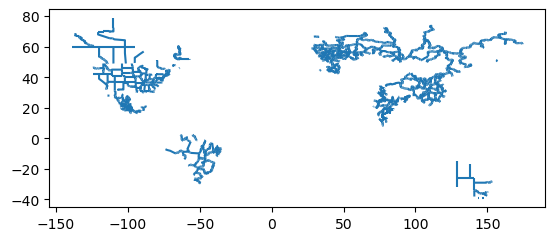

In [5]:
states.plot()

In [3]:
import geopandas as gpd
coastline = gpd.read_file('coastline/ne_10m_coastline.shp')
coastline.to_file('coastline.geojson', driver='GeoJSON')

<Axes: >

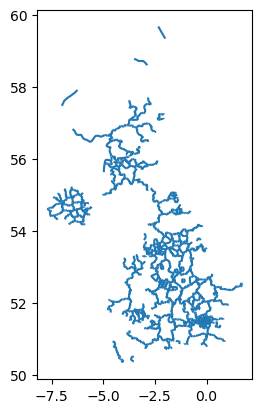

In [4]:
import geopandas as gpd
uk = adm1[adm1['ADM0_A3'] == 'GBR']
uk.plot()

<Axes: >

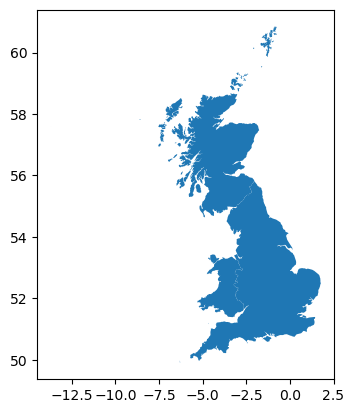

In [8]:
sub = gpd.read_file('ne_10m_admin_0_map_units/ne_10m_admin_0_map_units.shp')
uk = sub[sub['NAME'].isin(['England', 'Scotland', 'Wales'])]
uk.head()
uk.plot()

In [ ]:
bel = sub[sub['SOV_A3']=='BEL']
bel.head

,featurecla,scalerank,LABELRANK,SOVEREIGNT,SOV_A3,ADM0_DIF,LEVEL,TYPE,TLC,ADMIN,...,FCLASS_TR,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,geometry
63,Admin-0 map unit,0,9,Belgium,BEL,0,3,Geo unit,1,Belgium,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((2.5218 51.08754, 2.542 51.0968..."
64,Admin-0 map unit,0,9,Belgium,BEL,0,3,Geo unit,1,Belgium,...,None,None,None,None,None,None,None,None,None,"MULTIPOLYGON (((2.86673 50.70009, 2.8625 50.70..."
190,Admin-0 map unit,0,9,Belgium,BEL,0,3,Geo unit,1,Belgium,...,None,None,None,None,None,None,None,None,None,"POLYGON ((4.47975 50.79542, 4.39843 50.76779, ..."


In [9]:
from itertools import combinations 
from shapely.ops import unary_union 

uk = uk.to_crs(27700)

tol = 50
shared = []
for (n1, g1), (n2, g2) in combinations(uk.geometry.items(), 2): 
    line = g1.boundary.intersection(g2.buffer(tol))
    if not line.is_empty: 
        shared.append(line)
        print(n1, '/', n2, round(line.length/1000), 'km')

borders = gpd.GeoSeries([unary_union(shared)], crs=27700)


187 / 188 315 km
188 / 189 138 km


In [18]:
bel = bel.to_crs(27700)

tol = 50
shared = []
for (n1, g1), (n2, g2) in combinations(bel.geometry.items(), 2): 
    line = g1.boundary.intersection(g2.buffer(tol))
    if not line.is_empty: 
        shared.append(line)
        print(n1, '/', n2, round(line.length/1000), 'km')

bel_borders = gpd.GeoSeries([unary_union(shared)], crs=27700)

63 / 64 303 km
63 / 190 58 km


<Axes: >

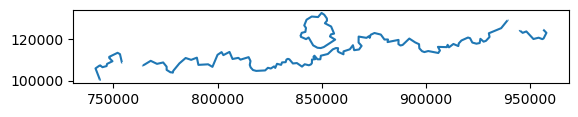

In [20]:
bel_borders.plot()

In [21]:
bel_borders = bel_borders.to_crs(4326)
bel_borders.to_file('bel_borders.geojson', driver='GeoJSON')

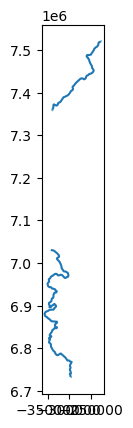

In [15]:
borders.plot()
borders = borders.to_crs(4326)
borders.to_file('uk_borders.geojson', driver='GeoJSON')